In [4]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["font.sans-serif"] = ["SimHei"]
plt.rcParams["axes.unicode_minus"] = False


In [5]:
BASE_DIR = Path(r"D:\数据集\colab数据\甜度预测数据\GNN")
INPUT_FILE = BASE_DIR / "SweetpredDB.csv"
OUTPUT_CSV = BASE_DIR / "SweetpredDB_classified.csv"
PIE_FIGURE = BASE_DIR / "sweetness_pie.png"

# 读取数据
data = pd.read_csv(INPUT_FILE)

# 检查数据列
if not {"Smiles", "logSw"}.issubset(data.columns):
    raise ValueError("CSV中必须包含 Smiles 和 logSw 两列")

data = data.dropna(subset=["logSw"]).copy()
data["Index"] = data.index

In [6]:
# 甜度分类
data["甜度"] = data["logSw"].apply(
    lambda x: "甜" if x > 1.5 else "中甜" if x >= 1.0 else "不甜"
)

# 输出logSw最高的5个分子
print("\n甜度最高的5个分子：")
print(
    data.nlargest(5, "logSw")[["Index", "Smiles", "logSw", "甜度"]]
    .to_string(index=False))


甜度最高的5个分子：
 Index                                                    Smiles  logSw 甜度
   626                             Oc1cc(ccc1OC)OCc1ccccc1C(=O)O  10.00  甜
   625            O1c2c(OC1)cccc2C\N=C(\Nc1ccc(cc1)C#N)/NCC(O)=O   7.35  甜
   623                OC(=O)CN/C(=N/c1ccc(cc1)C#N)/NCc1cc(ccc1)C   7.30  甜
   624                 OC(=O)CN/C(=N\c1ccc(cc1)C#N)/NC1CCCCCCCC1   7.30  甜
   622 O(C(=O)C(NC(=O)C(NC(=O)Nc1ccc(cc1)C#N)CC(O)=O)Cc1ccccc1)C   6.15  甜



甜度分布：
甜: 516 个，占比 82.30%
中甜: 63 个，占比 10.05%
不甜: 48 个，占比 7.66%


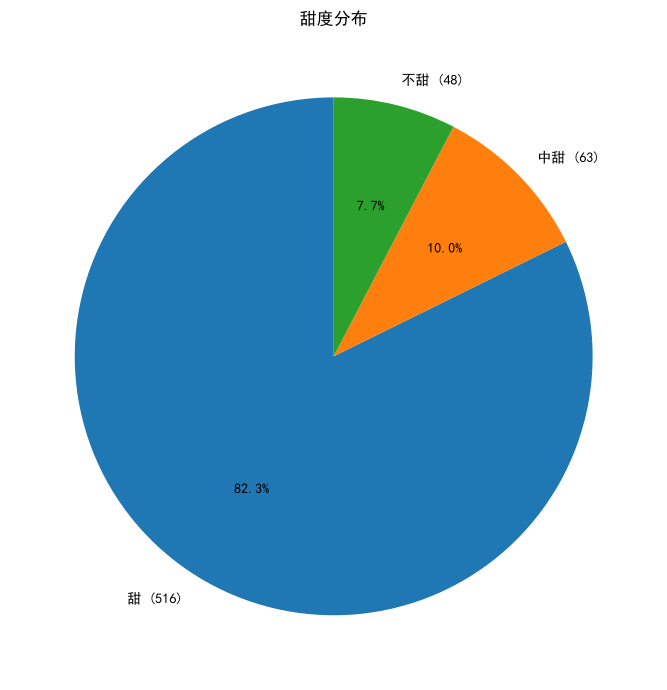


处理完成！
分类数据：D:\数据集\colab数据\甜度预测数据\GNN\SweetpredDB_classified.csv
饼图：D:\数据集\colab数据\甜度预测数据\GNN\sweetness_pie.png


In [7]:
# 统计甜度分布
distribution = data["甜度"].value_counts().reindex(
    ["甜", "中甜", "不甜"], fill_value=0
)

print("\n甜度分布：")
for label, count in distribution.items():
    print(f"{label}: {count} 个，占比 {count / len(data) * 100:.2f}%")

# 绘制饼图
plt.figure(figsize=(7, 7))
plt.pie(
    distribution,
    labels=[f"{x} ({y})" for x, y in distribution.items()],
    autopct="%1.1f%%",
    startangle=90
)
plt.title("甜度分布")
plt.tight_layout()
plt.savefig(PIE_FIGURE, dpi=300, bbox_inches="tight")
plt.show()

# 保存结果
data.to_csv(OUTPUT_CSV, index=False, encoding="utf-8-sig")

print("\n处理完成！")
print(f"分类数据：{OUTPUT_CSV}")
print(f"饼图：{PIE_FIGURE}")

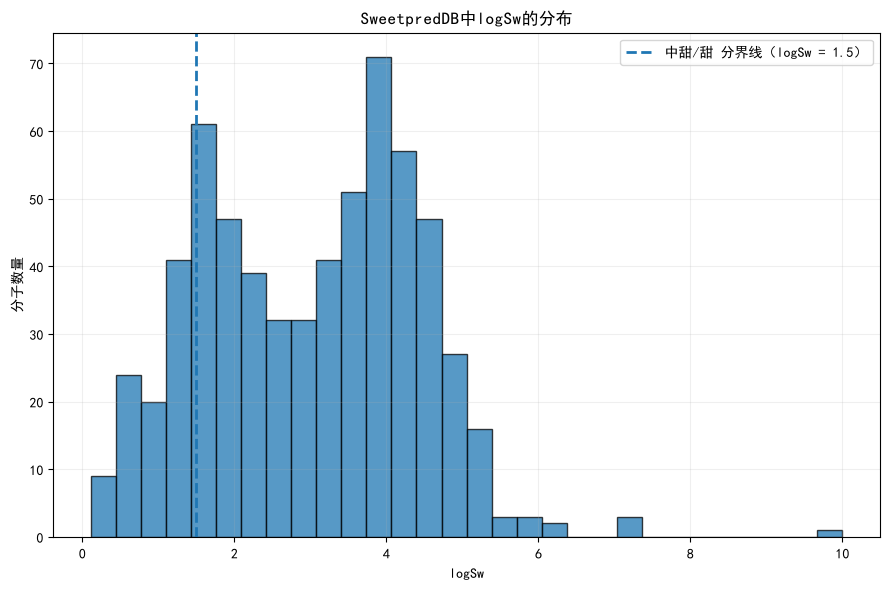

logSw分布图:D:\数据集\colab数据\甜度预测数据\GNN\logSw_distribution.png


In [8]:
# =========================
# 7. 绘制logSw分布直方图
# =========================
plt.figure(figsize=(9, 6))

plt.hist(
    data["logSw"],
    bins=30,
    edgecolor="black",
    alpha=0.75
)

# 添加甜度分类阈值
plt.axvline(
    1.5,
    linestyle="--",
    linewidth=2,
    label="中甜/甜 分界线（logSw = 1.5）"
)

plt.xlabel("logSw")
plt.ylabel("分子数量")
plt.title("SweetpredDB中logSw的分布")
plt.legend()
plt.grid(alpha=0.2)

plt.tight_layout()

# 保存图片
HIST_FILE = BASE_DIR / "logSw_distribution.png"
plt.savefig(
    HIST_FILE,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

print(f"logSw分布图:{HIST_FILE}")
